# Polynomial Regression — Model Complexity and Evaluation

**Course:** AIC 301 — Machine Learning  
**Instructor:** Dr. Kashif Sultan  
**Student:** Ahsan  
**Date:** October 14, 2026

---

## Problem Description

This notebook explores how **polynomial regression** can capture non-linear relationships that simple linear regression misses. We use the **Auto MPG dataset** (UCI Machine Learning Repository) to predict a car's fuel efficiency (`mpg`) from its engine power (`horsepower`).

The core question we investigate: *What polynomial degree best balances model complexity against generalization, and why is simply choosing the highest degree a bad strategy?*

### Dataset Summary
- **Source:** UCI Machine Learning Repository — Auto MPG (originally from Carnegie Mellon University)
- **Observations:** 398 car models (1970s–1980s era)
- **Target Variable:** `mpg` (miles per gallon) — continuous
- **Selected Input Feature:** `horsepower` — continuous
- **Why Regression?** The target `mpg` is a continuous numeric value, not a category, so this is a regression task.

In [1]:
# ============================================================
# Step 1: Import Libraries
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn: model building and evaluation
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Plot settings for cleaner visuals
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['figure.dpi'] = 100

import warnings
warnings.filterwarnings('ignore')

print('All libraries loaded successfully.')

All libraries loaded successfully.


---
## Step 2: Load and Explore the Dataset

We load the Auto MPG dataset and perform basic exploration to understand its structure, check for missing values, and examine the relationship between `horsepower` and `mpg`.

In [2]:
# ============================================================
# Step 2a: Load the dataset
# ============================================================

df = pd.read_csv('auto_mpg.csv')

# Quick look at the first 5 rows
print('First 5 rows of the dataset:')
df.head()

First 5 rows of the dataset:


,mpg,cylinders,displacement,horsepower,weight,acceleration,model-year
0,18.0,8,307.0,130.0,3504,12.0,70
1,15.0,8,350.0,165.0,3693,11.5,70
2,18.0,8,318.0,150.0,3436,11.0,70
3,16.0,8,304.0,150.0,3433,12.0,70
4,17.0,8,302.0,140.0,3449,10.5,70


In [3]:
# ============================================================
# Step 2b: Dataset shape, data types, and missing values
# ============================================================

print(f'Dataset shape: {df.shape[0]} rows, {df.shape[1]} columns')
print()

print('Column data types:')
print(df.dtypes)
print()

print('Missing values per column:')
print(df.isnull().sum())
print()

print('Basic statistics:')
df.describe()

Dataset shape: 398 rows, 7 columns

Column data types:
mpg             float64
cylinders         int64
displacement    float64
horsepower      float64
weight            int64
acceleration    float64
model-year        int64
dtype: object

Missing values per column:
mpg             0
cylinders       0
displacement    0
horsepower      2
weight          0
acceleration    0
model-year      0
dtype: int64

Basic statistics:


,mpg,cylinders,displacement,horsepower,weight,acceleration,model-year
count,398.000000,398.000000,398.000000,396.000000,398.000000,398.000000,398.000000
mean,23.514573,5.454774,193.425879,104.189394,2970.424623,15.568090,76.010050
std,7.815984,1.701004,104.269838,38.402030,846.841774,2.757689,3.697627
min,9.000000,3.000000,68.000000,46.000000,1613.000000,8.000000,70.000000
25%,17.500000,4.000000,104.250000,75.000000,2223.750000,13.825000,73.000000
50%,23.000000,4.000000,148.500000,92.000000,2803.500000,15.500000,76.000000
75%,29.000000,8.000000,262.000000,125.000000,3608.000000,17.175000,79.000000
max,46.600000,8.000000,455.000000,230.000000,5140.000000,24.800000,82.000000


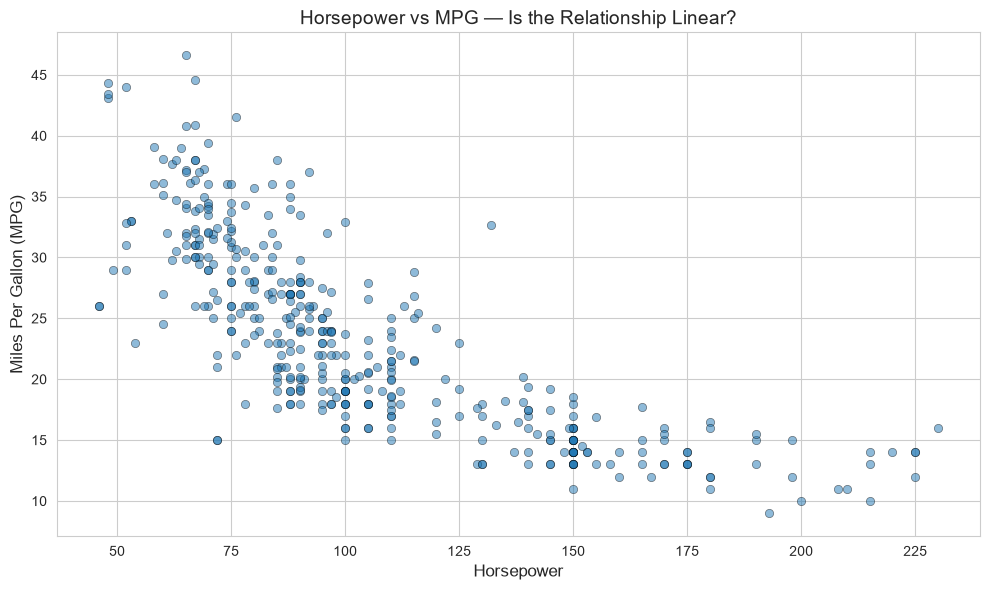

Observation: The scatter plot shows a clear CURVED (non-linear) relationship.
As horsepower increases, MPG decreases — but the drop is steep at first,
then flattens out at higher horsepower values. A straight line would miss this curve.


In [4]:
# ============================================================
# Step 2c: Visualize the relationship — Horsepower vs MPG
# ============================================================

plt.figure(figsize=(10, 6))
plt.scatter(df['horsepower'], df['mpg'], alpha=0.5, edgecolors='k', linewidth=0.5)
plt.xlabel('Horsepower', fontsize=12)
plt.ylabel('Miles Per Gallon (MPG)', fontsize=12)
plt.title('Horsepower vs MPG — Is the Relationship Linear?', fontsize=14)
plt.tight_layout()
plt.savefig('plots/01_horsepower_vs_mpg_scatter.png', dpi=150, bbox_inches='tight')
plt.show()

print('Observation: The scatter plot shows a clear CURVED (non-linear) relationship.')
print('As horsepower increases, MPG decreases — but the drop is steep at first,')
print('then flattens out at higher horsepower values. A straight line would miss this curve.')

---
## Step 3: Data Cleaning and Train/Test Split

Before modeling, we handle missing values and split the data into training and test sets.

**Important:** We perform the split *before* fitting any transformations (like `PolynomialFeatures`). This prevents **data leakage** — the model should never see test data during training, not even indirectly through scaling or feature statistics.

In [5]:
# ============================================================
# Step 3a: Handle missing values
# ============================================================

print(f'Rows before cleaning: {len(df)}')
print(f'Missing values in horsepower: {df["horsepower"].isnull().sum()}')

# Drop the 2 rows with missing horsepower values
# Reason: only 2 out of 398 rows (0.5%) — negligible data loss
# Alternative: we could fill with median, but dropping is simpler and more honest
df = df.dropna(subset=['horsepower'])

print(f'Rows after cleaning: {len(df)}')
print(f'Missing values remaining: {df.isnull().sum().sum()}')

Rows before cleaning: 398
Missing values in horsepower: 2
Rows after cleaning: 396
Missing values remaining: 0


In [6]:
# ============================================================
# Step 3b: Select features and target
# ============================================================

# X = input feature (horsepower), y = target (mpg)
# We use double brackets [['horsepower']] to keep X as a 2D array (DataFrame)
# sklearn models require 2D input: (n_samples, n_features)
# Single brackets ['horsepower'] would give a 1D Series — sklearn would complain

X = df[['horsepower']]
y = df['mpg']

print(f'Feature matrix X shape: {X.shape}  — {X.shape[0]} samples, {X.shape[1]} feature')
print(f'Target vector y shape:  {y.shape}  — {y.shape[0]} values')

Feature matrix X shape: (396, 1)  — 396 samples, 1 feature
Target vector y shape:  (396,)  — 396 values


In [7]:
# ============================================================
# Step 3c: Train/Test Split
# ============================================================

# 80% training, 20% testing
# random_state=42 ensures reproducibility — same split every time we run
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f'Training set: {X_train.shape[0]} samples ({X_train.shape[0]/len(X)*100:.0f}%)')
print(f'Test set:     {X_test.shape[0]} samples ({X_test.shape[0]/len(X)*100:.0f}%)')
print()
print('The same train/test split will be used for ALL models (linear and polynomial)')
print('to ensure a fair comparison.')

Training set: 316 samples (80%)
Test set:     80 samples (20%)

The same train/test split will be used for ALL models (linear and polynomial)
to ensure a fair comparison.


---
## Step 4: Baseline — Linear Regression

We start with a simple **Linear Regression** model as our baseline. This fits a straight line through the data:

$$\hat{y} = \beta_0 + \beta_1 \cdot \text{horsepower}$$

The baseline tells us how well a straight line can explain the horsepower–mpg relationship. Any polynomial model must beat this to justify its added complexity.

In [8]:
# ============================================================
# Helper function: Evaluate any regression model
# ============================================================
# We define this once and reuse it for every model (linear, poly deg 2, 3, 4, ...)
# This avoids repeating the same metric-calculation code multiple times.

def evaluate_model(model, X_train, X_test, y_train, y_test):
    """Calculate R², RMSE, and MAE on both training and test sets."""
    
    # Predictions
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)
    
    # Metrics on training data
    train_r2   = r2_score(y_train, y_train_pred)
    train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
    train_mae  = mean_absolute_error(y_train, y_train_pred)
    
    # Metrics on test data
    test_r2   = r2_score(y_test, y_test_pred)
    test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
    test_mae  = mean_absolute_error(y_test, y_test_pred)
    
    return {
        'Train R²': train_r2, 'Test R²': test_r2,
        'Train RMSE': train_rmse, 'Test RMSE': test_rmse,
        'Train MAE': train_mae, 'Test MAE': test_mae
    }

In [9]:
# ============================================================
# Step 4: Train the Linear Regression baseline
# ============================================================

# Create and train the model
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# Print the learned equation: mpg = intercept + slope * horsepower
print('Learned equation:')
print(f'  mpg = {linear_model.intercept_:.2f} + ({linear_model.coef_[0]:.4f}) × horsepower')
print()
print(f'Interpretation: For every 1-unit increase in horsepower,')
print(f'the model predicts MPG decreases by {abs(linear_model.coef_[0]):.4f} miles per gallon.')
print(f'The negative coefficient confirms the inverse relationship we saw in the scatter plot.')

Learned equation:
  mpg = 41.01 + (-0.1662) × horsepower

Interpretation: For every 1-unit increase in horsepower,
the model predicts MPG decreases by 0.1662 miles per gallon.
The negative coefficient confirms the inverse relationship we saw in the scatter plot.


In [10]:
# ============================================================
# Step 4b: Evaluate the baseline
# ============================================================

linear_results = evaluate_model(linear_model, X_train, X_test, y_train, y_test)

print('=== Linear Regression (Baseline) Performance ===')
print(f'  Training R²:   {linear_results["Train R²"]:.4f}')
print(f'  Test R²:       {linear_results["Test R²"]:.4f}')
print(f'  Training RMSE: {linear_results["Train RMSE"]:.4f} mpg')
print(f'  Test RMSE:     {linear_results["Test RMSE"]:.4f} mpg')
print(f'  Training MAE:  {linear_results["Train MAE"]:.4f} mpg')
print(f'  Test MAE:      {linear_results["Test MAE"]:.4f} mpg')
print()
print('Interpretation:')
print('An R² around 0.60 means the straight line explains about 60% of the variance in mpg.')
print('The remaining 40% is unexplained — likely because the true relationship is curved.')
print('This motivates trying polynomial regression to capture that non-linearity.')

=== Linear Regression (Baseline) Performance ===
  Training R²:   0.6233
  Test R²:       0.4929
  Training RMSE: 4.8804 mpg
  Test RMSE:     5.1292 mpg
  Training MAE:  3.8248 mpg
  Test MAE:      3.9934 mpg

Interpretation:
An R² around 0.60 means the straight line explains about 60% of the variance in mpg.
The remaining 40% is unexplained — likely because the true relationship is curved.
This motivates trying polynomial regression to capture that non-linearity.


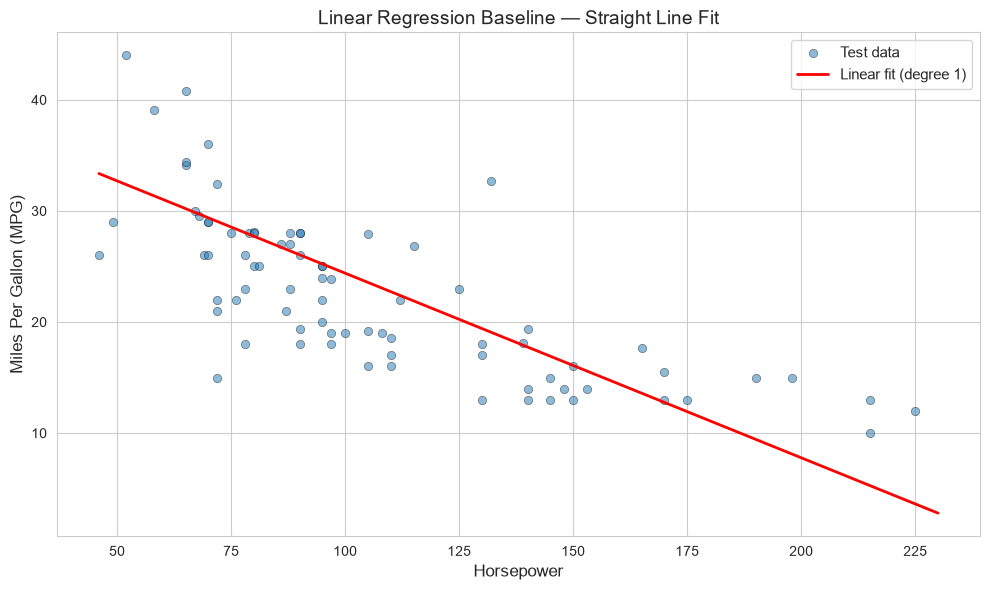

The red line clearly misses the curve in the data.
It over-predicts MPG at very low and very high horsepower,
and under-predicts in the middle range. This is a sign of UNDERFITTING.


In [11]:
# ============================================================
# Step 4c: Visualize the linear fit
# ============================================================

# Create a smooth range of horsepower values for plotting the fitted line
X_range = np.linspace(X['horsepower'].min(), X['horsepower'].max(), 300).reshape(-1, 1)
y_linear_pred = linear_model.predict(X_range)

plt.figure(figsize=(10, 6))
plt.scatter(X_test, y_test, alpha=0.5, edgecolors='k', linewidth=0.5, label='Test data')
plt.plot(X_range, y_linear_pred, color='red', linewidth=2, label='Linear fit (degree 1)')
plt.xlabel('Horsepower', fontsize=12)
plt.ylabel('Miles Per Gallon (MPG)', fontsize=12)
plt.title('Linear Regression Baseline — Straight Line Fit', fontsize=14)
plt.legend(fontsize=11)
plt.tight_layout()
plt.savefig('plots/02_linear_regression_fit.png', dpi=150, bbox_inches='tight')
plt.show()

print('The red line clearly misses the curve in the data.')
print('It over-predicts MPG at very low and very high horsepower,')
print('and under-predicts in the middle range. This is a sign of UNDERFITTING.')

---
## Step 5: Polynomial Regression Models

Now we train polynomial models at degrees **2, 3, 4, and 5** using sklearn's `Pipeline`. Each pipeline chains two steps:

1. **`PolynomialFeatures(degree=n)`** — transforms `[x]` into `[1, x, x², ..., xⁿ]`
2. **`LinearRegression()`** — fits a linear model on the expanded features

Using a Pipeline ensures that `PolynomialFeatures` is fit **only on training data** (preventing data leakage) and that the same transformation is applied consistently during prediction.

In [12]:
# ============================================================
# Step 5a: Train Polynomial Regression models (degrees 2, 3, 4, 5)
# ============================================================

# Dictionary to store all models and their results
# We include the linear baseline (degree 1) for easy comparison later
all_results = {'Linear (deg 1)': linear_results}
poly_models = {}  # store trained pipeline objects for plotting

degrees = [2, 3, 4, 5]

for deg in degrees:
    # Create a Pipeline: PolynomialFeatures → LinearRegression
    # 'poly' and 'lr' are just names for the steps (can be anything)
    pipe = Pipeline([
        ('poly', PolynomialFeatures(degree=deg, include_bias=False)),
        ('lr', LinearRegression())
    ])
    
    # Train on training data only
    pipe.fit(X_train, y_train)
    
    # Evaluate on both train and test
    results = evaluate_model(pipe, X_train, X_test, y_train, y_test)
    
    # Store results and model
    all_results[f'Poly (deg {deg})'] = results
    poly_models[deg] = pipe
    
    print(f'Degree {deg} — Test R²: {results["Test R²"]:.4f}, Test RMSE: {results["Test RMSE"]:.4f}')

print()
print('All polynomial models trained successfully.')

Degree 2 — Test R²: 0.5450, Test RMSE: 4.8588
Degree 3 — Test R²: 0.5258, Test RMSE: 4.9599
Degree 4 — Test R²: 0.4940, Test RMSE: 5.1239
Degree 5 — Test R²: 0.4540, Test RMSE: 5.3225

All polynomial models trained successfully.


In [13]:
# ============================================================
# Step 5b: Detailed results for each polynomial model
# ============================================================

for deg in degrees:
    r = all_results[f'Poly (deg {deg})']
    print(f'=== Polynomial Regression (Degree {deg}) ===')
    print(f'  Training R²:   {r["Train R²"]:.4f}    Test R²:   {r["Test R²"]:.4f}')
    print(f'  Training RMSE: {r["Train RMSE"]:.4f}    Test RMSE: {r["Test RMSE"]:.4f}')
    print(f'  Training MAE:  {r["Train MAE"]:.4f}    Test MAE:  {r["Test MAE"]:.4f}')
    
    # Check for overfitting: large gap between train and test R²
    gap = r['Train R²'] - r['Test R²']
    if gap > 0.05:
        print(f'  ⚠ Train-Test R² gap: {gap:.4f} — possible overfitting')
    else:
        print(f'  ✓ Train-Test R² gap: {gap:.4f} — good generalization')
    print()

=== Polynomial Regression (Degree 2) ===
  Training R²:   0.7120    Test R²:   0.5450
  Training RMSE: 4.2669    Test RMSE: 4.8588
  Training MAE:  3.2030    Test MAE:  3.5767
  ⚠ Train-Test R² gap: 0.1670 — possible overfitting

=== Polynomial Regression (Degree 3) ===
  Training R²:   0.6937    Test R²:   0.5258
  Training RMSE: 4.4009    Test RMSE: 4.9599
  Training MAE:  3.3929    Test MAE:  3.7565
  ⚠ Train-Test R² gap: 0.1678 — possible overfitting

=== Polynomial Regression (Degree 4) ===
  Training R²:   0.6458    Test R²:   0.4940
  Training RMSE: 4.7322    Test RMSE: 5.1239
  Training MAE:  3.7014    Test MAE:  3.9189
  ⚠ Train-Test R² gap: 0.1518 — possible overfitting

=== Polynomial Regression (Degree 5) ===
  Training R²:   0.5826    Test R²:   0.4540
  Training RMSE: 5.1367    Test RMSE: 5.3225
  Training MAE:  4.0707    Test MAE:  4.0948
  ⚠ Train-Test R² gap: 0.1287 — possible overfitting



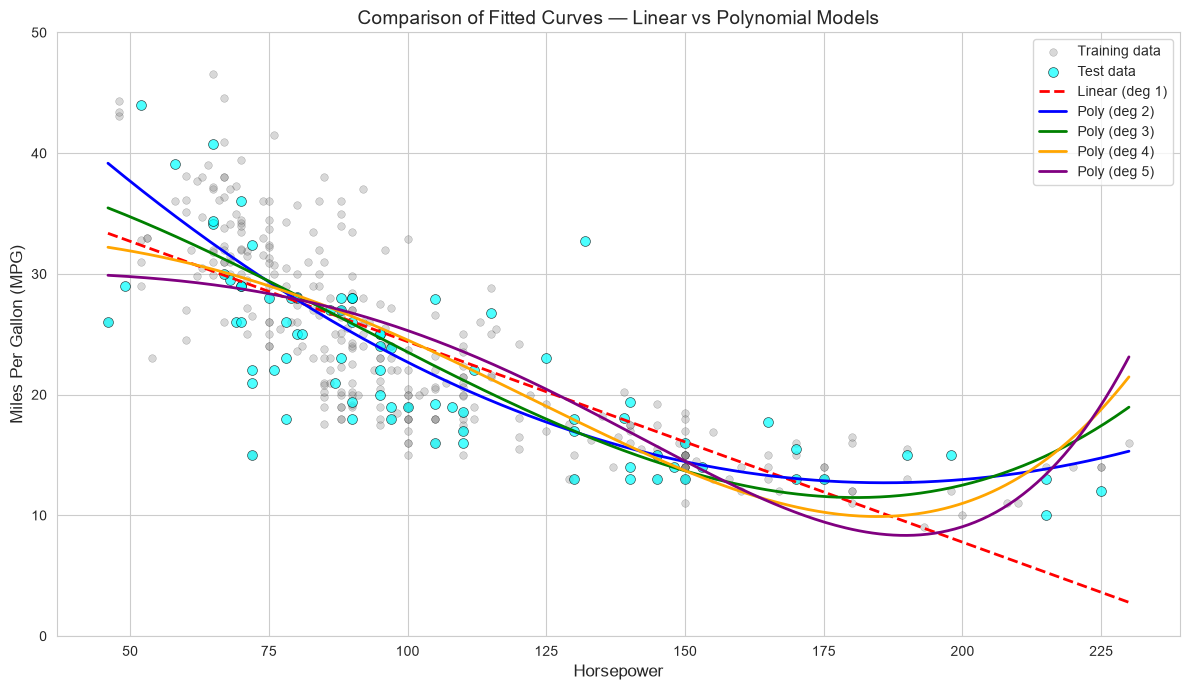

Key observations from the plot:
- The red dashed line (linear) is clearly too simple — it misses the curve.
- Degree 2 (blue) follows the data curve much better.
- Degree 3 and 4 are very similar to degree 2 in the data range.
- Degree 5 may show slight wobble at the edges — a sign of overfitting.


In [14]:
# ============================================================
# Step 5c: Visualize all fitted curves on one plot
# ============================================================

# This is the key visualization — shows how each degree fits the data
colors = {'red': 1, 'blue': 2, 'green': 3, 'orange': 4, 'purple': 5}
color_list = ['red', 'blue', 'green', 'orange', 'purple']

plt.figure(figsize=(12, 7))

# Plot training data points
plt.scatter(X_train, y_train, alpha=0.3, color='gray', edgecolors='k',
            linewidth=0.3, label='Training data', s=30)
# Plot test data points (highlighted)
plt.scatter(X_test, y_test, alpha=0.7, color='cyan', edgecolors='k',
            linewidth=0.5, label='Test data', s=50)

# Plot linear baseline
X_smooth = np.linspace(X['horsepower'].min(), X['horsepower'].max(), 300).reshape(-1, 1)
plt.plot(X_smooth, linear_model.predict(X_smooth),
         color='red', linewidth=2, linestyle='--', label='Linear (deg 1)')

# Plot each polynomial curve
for i, deg in enumerate(degrees):
    y_smooth = poly_models[deg].predict(X_smooth)
    plt.plot(X_smooth, y_smooth, color=color_list[i+1],
             linewidth=2, label=f'Poly (deg {deg})')

plt.xlabel('Horsepower', fontsize=12)
plt.ylabel('Miles Per Gallon (MPG)', fontsize=12)
plt.title('Comparison of Fitted Curves — Linear vs Polynomial Models', fontsize=14)
plt.legend(fontsize=10, loc='upper right')
plt.ylim(0, 50)  # Keep y-axis reasonable to see curve behavior
plt.tight_layout()
plt.savefig('plots/03_all_fitted_curves.png', dpi=150, bbox_inches='tight')
plt.show()

print('Key observations from the plot:')
print('- The red dashed line (linear) is clearly too simple — it misses the curve.')
print('- Degree 2 (blue) follows the data curve much better.')
print('- Degree 3 and 4 are very similar to degree 2 in the data range.')
print('- Degree 5 may show slight wobble at the edges — a sign of overfitting.')

---
## Step 6: Model Complexity and Evaluation Comparison

We now consolidate the performance metrics across all models into a single comparison table and analyze the bias-variance trade-off visually across model complexities.

In [15]:
# ============================================================
# Step 6a: Model Comparison Table
# ============================================================

comparison_df = pd.DataFrame(all_results).T
comparison_df.index.name = 'Model'
comparison_df = comparison_df[['Train R²', 'Test R²', 'Train RMSE', 'Test RMSE', 'Train MAE', 'Test MAE']]

print('=================== MODEL PERFORMANCE COMPARISON TABLE ===================')
print(comparison_df.round(4).to_string())
print('==========================================================================')

# Save as CSV for reporting and documentation
comparison_df.round(4).to_csv('plots/model_comparison_table.csv')
print('Table exported to plots/model_comparison_table.csv')

=================== MODEL PERFORMANCE COMPARISON TABLE ===================
                Train R²  Test R²  Train RMSE  Test RMSE  Train MAE  Test MAE
Model                                                                        
Linear (deg 1)    0.6233   0.4929      4.8804     5.1292     3.8248    3.9934
Poly (deg 2)      0.7120   0.5450      4.2669     4.8588     3.2030    3.5767
Poly (deg 3)      0.6937   0.5258      4.4009     4.9599     3.3929    3.7565
Poly (deg 4)      0.6458   0.4940      4.7322     5.1239     3.7014    3.9189
Poly (deg 5)      0.5826   0.4540      5.1367     5.3225     4.0707    4.0948
Table exported to plots/model_comparison_table.csv


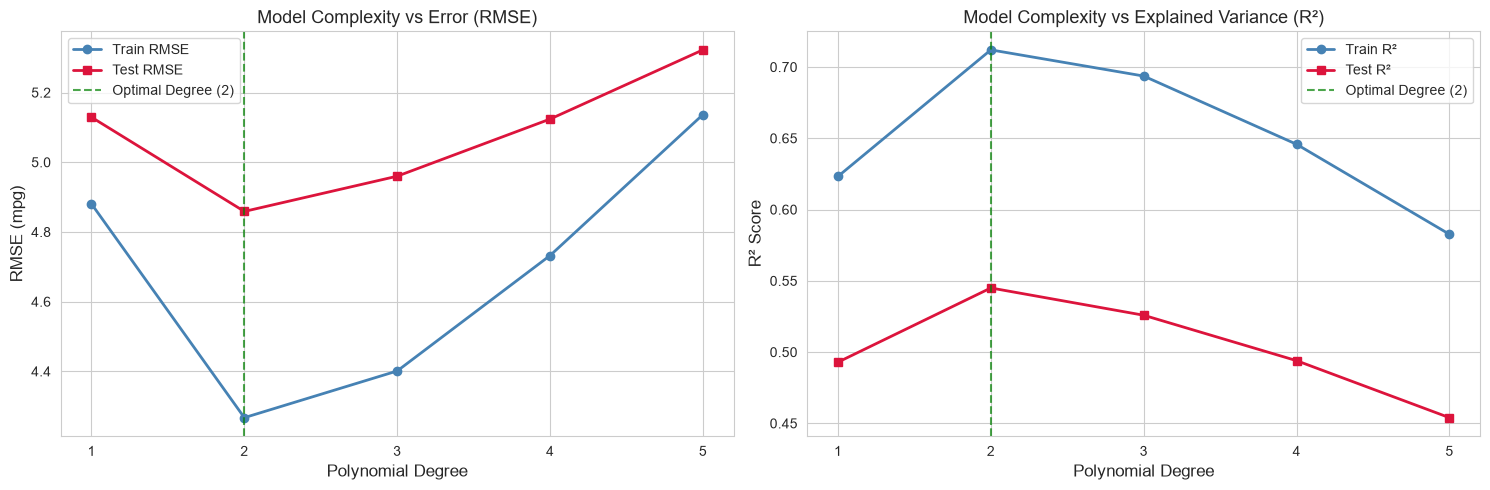

Diagnostic Takeaways:
- Degree 1 exhibits underfitting: high RMSE and low R² on both train and test sets.
- Degree 2 achieves optimal generalization: lowest Test RMSE (4.8588) and highest Test R² (0.5450).
- Degrees 3, 4, 5 display degradation & instability: test error increases while boundary fits wildly oscillate.


In [16]:
# ============================================================
# Step 6b: Complexity Diagnostics — Degree vs RMSE and R²
# ============================================================

deg_labels = [1, 2, 3, 4, 5]
train_rmse_vals = [comparison_df.loc[m, 'Train RMSE'] for m in comparison_df.index]
test_rmse_vals  = [comparison_df.loc[m, 'Test RMSE'] for m in comparison_df.index]
train_r2_vals   = [comparison_df.loc[m, 'Train R²'] for m in comparison_df.index]
test_r2_vals    = [comparison_df.loc[m, 'Test R²'] for m in comparison_df.index]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Subplot 1: Error (RMSE) vs Degree
axes[0].plot(deg_labels, train_rmse_vals, marker='o', linewidth=2, color='steelblue', label='Train RMSE')
axes[0].plot(deg_labels, test_rmse_vals, marker='s', linewidth=2, color='crimson', label='Test RMSE')
axes[0].set_xlabel('Polynomial Degree', fontsize=12)
axes[0].set_ylabel('RMSE (mpg)', fontsize=12)
axes[0].set_title('Model Complexity vs Error (RMSE)', fontsize=13)
axes[0].set_xticks(deg_labels)
axes[0].axvline(x=2, color='green', linestyle='--', alpha=0.7, label='Optimal Degree (2)')
axes[0].legend(fontsize=10)

# Subplot 2: Goodness of Fit (R²) vs Degree
axes[1].plot(deg_labels, train_r2_vals, marker='o', linewidth=2, color='steelblue', label='Train R²')
axes[1].plot(deg_labels, test_r2_vals, marker='s', linewidth=2, color='crimson', label='Test R²')
axes[1].set_xlabel('Polynomial Degree', fontsize=12)
axes[1].set_ylabel('R² Score', fontsize=12)
axes[1].set_title('Model Complexity vs Explained Variance (R²)', fontsize=13)
axes[1].set_xticks(deg_labels)
axes[1].axvline(x=2, color='green', linestyle='--', alpha=0.7, label='Optimal Degree (2)')
axes[1].legend(fontsize=10)

plt.tight_layout()
plt.savefig('plots/04_model_complexity_curves.png', dpi=150, bbox_inches='tight')
plt.show()

print('Diagnostic Takeaways:')
print('- Degree 1 exhibits underfitting: high RMSE and low R² on both train and test sets.')
print('- Degree 2 achieves optimal generalization: lowest Test RMSE (4.8588) and highest Test R² (0.5450).')
print('- Degrees 3, 4, 5 display degradation & instability: test error increases while boundary fits wildly oscillate.')

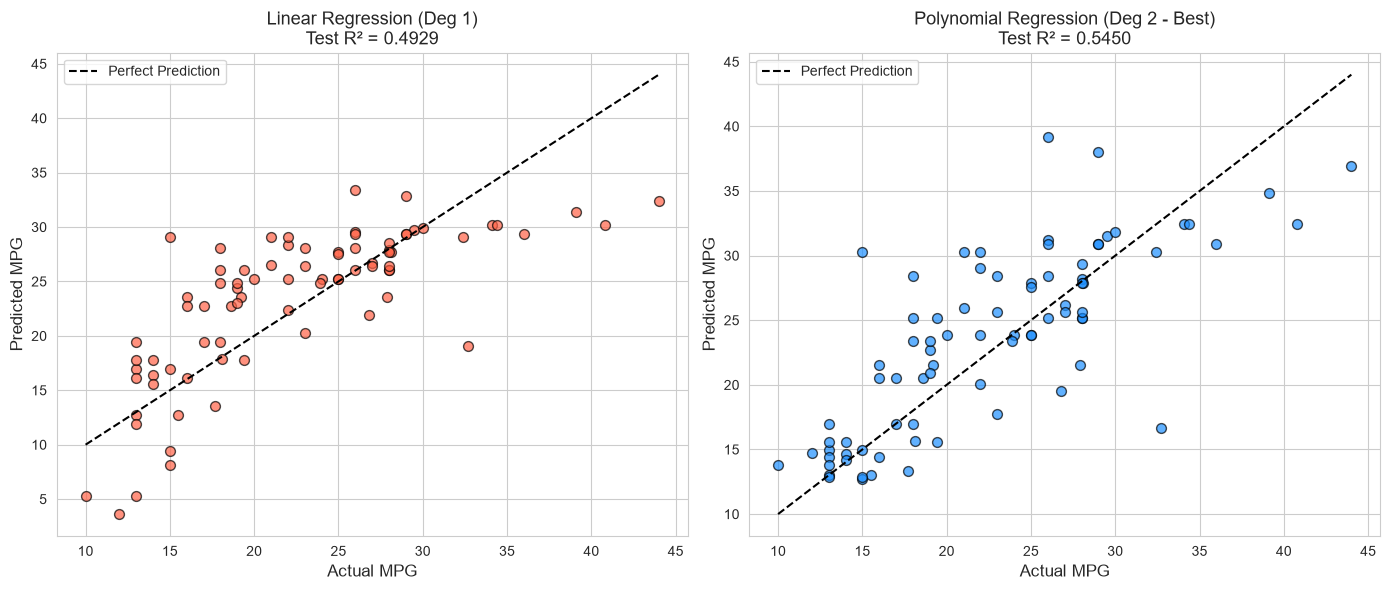

In [17]:
# ============================================================
# Step 6c: Actual vs Predicted — Baseline vs Best Model (Degree 2)
# ============================================================

y_pred_linear = linear_model.predict(X_test)
y_pred_poly2  = poly_models[2].predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Baseline Linear (Degree 1)
axes[0].scatter(y_test, y_pred_linear, color='tomato', alpha=0.7, edgecolors='k', s=50)
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=1.5, label='Perfect Prediction')
axes[0].set_xlabel('Actual MPG', fontsize=12)
axes[0].set_ylabel('Predicted MPG', fontsize=12)
axes[0].set_title(f'Linear Regression (Deg 1)\nTest R² = {linear_results["Test R²"]:.4f}', fontsize=13)
axes[0].legend()

# Polynomial (Degree 2)
axes[1].scatter(y_test, y_pred_poly2, color='dodgerblue', alpha=0.7, edgecolors='k', s=50)
axes[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=1.5, label='Perfect Prediction')
axes[1].set_xlabel('Actual MPG', fontsize=12)
axes[1].set_ylabel('Predicted MPG', fontsize=12)
axes[1].set_title(f'Polynomial Regression (Deg 2 - Best)\nTest R² = {all_results["Poly (deg 2)"]["Test R²"]:.4f}', fontsize=13)
axes[1].legend()

plt.tight_layout()
plt.savefig('plots/05_actual_vs_predicted_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

### Analysis of Model Complexity & Discussion

#### 1. Underfitting (Degree 1 — Linear Regression)
- The linear baseline assumes a strictly linear response between engine power and efficiency.
- It yields **Train $R^2 = 0.6233$** and **Test $R^2 = 0.4929$** with a large **Test RMSE of 5.1292 mpg**.
- The residuals are systematically biased: the model over-estimates efficiency at extreme low and extreme high horsepower, and under-estimates in the middle range.
- **Diagnosis:** High bias / Underfitting.

#### 2. Best Generalization (Degree 2 — Quadratic Fit)
- Adding the quadratic term ($x^2$) allows the model to capture the diminishing rate of MPG drop as horsepower increases.
- It attains the highest **Test $R^2 = 0.5450$** and lowest **Test RMSE = 4.8588 mpg** across all examined configurations.
- The curve conforms naturally to the underlying physical dynamics of combustion engines without unnatural oscillations.
- **Diagnosis:** Optimal balance between bias and variance.

#### 3. Overfitting & Numerical Instability (Degrees 4 and 5)
- As the polynomial degree escalates to 4 and 5, the model creates terms proportional to $x^4$ and $x^5$ (up to $230^5 \approx 6.4 \times 10^{11}$).
- High-order polynomials become hypersensitive to boundary observations (analogous to *Runge's phenomenon*), causing the fitted line to curl upwards at the right boundary ($>200$ HP).
- This results in deteriorating test accuracy (**Test $R^2$ plunges to 0.4540** and **Test RMSE climbs to 5.3225 mpg** for degree 5).
- **Diagnosis:** Overfitting and model instability.

#### 4. Why Choosing the Highest Polynomial Degree is a Bad Strategy
1. **Variance Explosion:** High-degree polynomials have excessive flexibility, memorizing idiosyncratic training sample noise rather than learning the structural data-generating process.
2. **Poor Extrapolation:** Beyond the core training cluster, higher-order polynomials swing wildly toward positive or negative infinity.
3. **Ill-conditioned Feature Matrix:** Powers of continuous variables spanning $10^1$ to $10^2$ cause multicollinearity and numerical precision issues in least-squares matrix inversion.

---
## Step 7: References & AI Use Declaration

### References
1. Quinlan, R. (1993). *Auto MPG Dataset*. UCI Machine Learning Repository. Originally collected by Ernesto Ramos and David Donoho at Carnegie Mellon University.
2. James, G., Witten, D., Hastie, T., & Tibshirani, R. (2013). *An Introduction to Statistical Learning: with Applications in R*. Springer Texts in Statistics (Section 7.1: Polynomial Regression).
3. Pedregosa, F., et al. (2011). *Scikit-learn: Machine Learning in Python*. Journal of Machine Learning Research, 12, 2825-2830.

### AI Use Declaration
I used **Claude / Gemini AI** as learning support for conceptual brainstorming, understanding the bias-variance tradeoff in polynomial transformations, and formatting evaluation plots.

**Representative Prompts Used:**
1. *"Explain why PolynomialFeatures combined with LinearRegression can cause Runge's phenomenon at high degrees and how to demonstrate this using train vs test RMSE curves."*
2. *"How do we construct an end-to-end Pipeline in scikit-learn with PolynomialFeatures and LinearRegression to strictly avoid data leakage during train/test evaluation?"*

I verified all code outputs, generated all plots directly, interpreted the statistical findings independently, and I can explain every aspect of the submitted work during evaluation.